## Simple Linear Regression

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression



In [53]:
# =========================================================
# 1. LOAD DATA
# =========================================================

df = pd.read_csv(
    r"D:\VS code Files\Machine Learning\Practice\Linear_regression\1.01. Simple linear regression.csv"
)

print(df.head())
print("Shape:", df.shape)



    SAT   GPA
0  1714  2.40
1  1664  2.52
2  1760  2.54
3  1685  2.74
4  1693  2.83
Shape: (84, 2)


In [54]:

# =========================================================
# 2. DEFINE X AND y
# =========================================================

X = df['SAT']
y = df['GPA']



In [55]:
# =========================================================
# 3. TRAIN-TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (67,)
X_test shape: (17,)
y_train shape: (67,)
y_test shape: (17,)


In [56]:
def simple_lr(x, y):

    # Check whether X and y have same number of observations
    if len(x) != len(y):
        raise ValueError("X and y must have the same number of observations")

    # Mean of X and y
    x_bar = x.mean()
    y_bar = y.mean()

    # Initialize numerator and denominator
    num = 0
    deno = 0

    # Calculate numerator and denominator
    for i, j in zip(x, y):

        num += (i - x_bar) * (j - y_bar)
        deno += (i - x_bar) ** 2

    # Avoid division by zero
    if deno == 0:
        raise ValueError("X cannot contain the same value for all observations")

    # Calculate slope
    m = num / deno

    # Calculate intercept
    c = y_bar - m * x_bar

    return m,c

In [57]:
# =========================================================
# 5. TRAIN OUR MODEL
# =========================================================

slope, intercept = simple_lr(X_train, y_train)

print("\nOur Model")
print("Slope =", slope)
print("Intercept =", intercept)


Our Model
Slope = 0.0014686969826413156
Intercept = 0.6258624722253541


In [58]:

# =========================================================
# 6. PREDICTION FUNCTION
# =========================================================

def predict(x, m, c):

    return m * x + c

In [59]:
# =========================================================
# 7. PREDICT ON TEST DATA
# =========================================================

y_pred = predict(X_test, slope, intercept)

print("\nActual vs Predicted")

comparison = pd.DataFrame({
    "Actual GPA": y_test.values,
    "Predicted GPA": y_pred.values
})

print(comparison)


Actual vs Predicted
    Actual GPA  Predicted GPA
0         3.60       3.466322
1         2.40       3.143209
2         3.47       3.241612
3         3.20       3.068306
4         3.08       3.174052
5         3.59       3.464854
6         3.02       3.174052
7         3.17       3.331202
8         2.83       3.112366
9         3.52       3.316515
10        3.37       3.364982
11        3.40       3.498634
12        3.31       3.341483
13        3.73       3.544163
14        3.47       3.397294
15        3.44       3.385544
16        3.29       3.350295


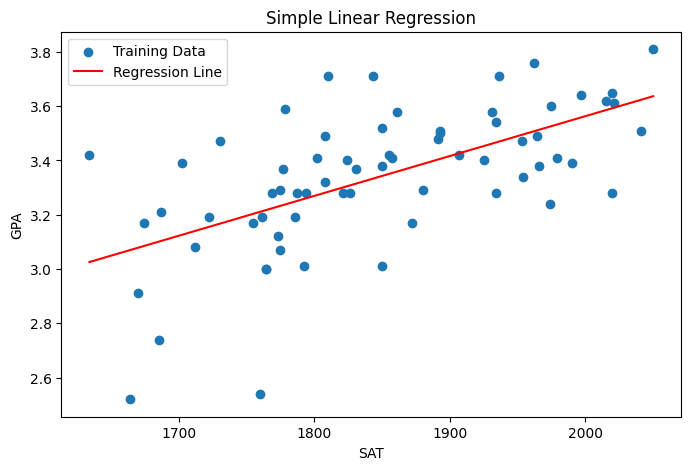

In [62]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label="Training Data")

# Sort X values for a clean regression line
x_line = np.sort(X_train)

y_line = predict(
    x_line,
    slope,
    intercept
)

plt.plot(
    x_line,
    y_line,
    label="Regression Line",
    color = 'red'
)

plt.xlabel("SAT")
plt.ylabel("GPA")
plt.title("Simple Linear Regression")

plt.legend()
plt.show()

In [63]:
# =========================================================
# 12. COMPARE WITH SKLEARN
# =========================================================

# sklearn expects X as 2D
X_train_2d = X_train.values.reshape(-1, 1)
X_test_2d = X_test.values.reshape(-1, 1)

# Create sklearn model
slr = LinearRegression()

# Train sklearn model
slr.fit(X_train_2d, y_train)

# sklearn prediction
sklearn_pred = slr.predict(X_test_2d)

print("\nSklearn Model")

print("Slope =", slr.coef_[0])
print("Intercept =", slr.intercept_)



Sklearn Model
Slope = 0.001468696982641316
Intercept = 0.6258624722253536
